I0000 00:00:1794307239.280989      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794307259.213053      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
Training Directory: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset
Validation Directory: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset
Testing Directory: None
Found 175767 files belonging to 3 classes.


E0000 00:00:1794307511.093921      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



Total Classes: 3

Plant Disease Classes:
['New Plant Diseases Dataset(Augmented)', 'new plant diseases dataset(augmented)', 'test']
Found 175767 files belonging to 3 classes.


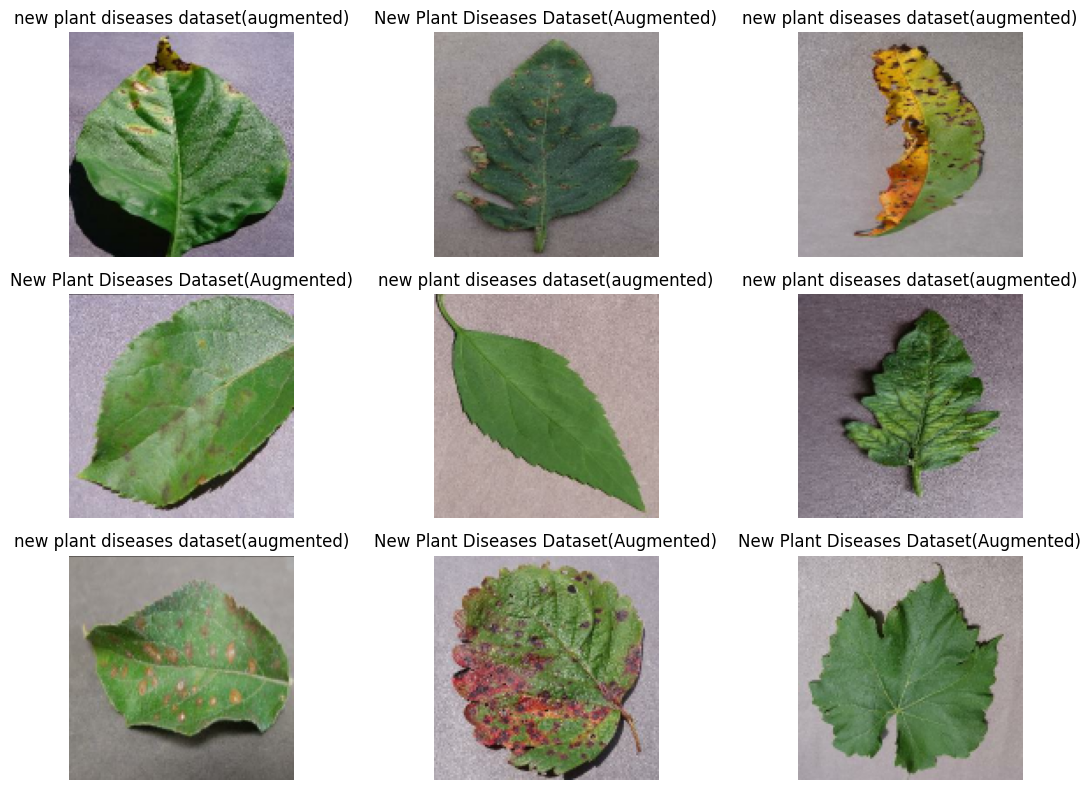

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,583,747 (17.49 MB)

 Trainable params: 4,583,747 (17.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
 128/5493 ━━━━━━━━━━━━━━━━━━━━ 1:00:54 681ms/step - accuracy: 0.5100 - loss: 0.7780

In [ ]:

# ============================================================
# PLANT DISEASE CLASSIFICATION USING CNN
# Dataset: New Plant Diseases Dataset (Augmented)
# Platform: Kaggle Notebook
# ============================================================

# 1. IMPORT LIBRARIES

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)

# ============================================================
# 2. DATASET LOCATION
# ============================================================

# Kaggle automatically mounts added datasets inside /kaggle/input

INPUT_DIR = Path("/kaggle/input")

TRAIN_DIR = None
VALID_DIR = None
TEST_DIR = None

# Automatically find train and valid folders
for root, dirs, files in os.walk(INPUT_DIR):
    if "train" in dirs and "valid" in dirs:
        TRAIN_DIR = Path(root) / "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/"
        VALID_DIR = Path(root) / "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/"

        if "test" in dirs:
            TEST_DIR = Path(root) / "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test"

        break

if TRAIN_DIR is None or VALID_DIR is None:
    raise FileNotFoundError(
        "Dataset not found! Add New Plant Diseases Dataset "
        "using Kaggle Add Input."
    )

print("Training Directory:", TRAIN_DIR)
print("Validation Directory:", VALID_DIR)
print("Testing Directory:", TEST_DIR)

# ============================================================
# 3. BASIC CONFIGURATION
# ============================================================

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 20
SEED = 42

# ============================================================
# 4. LOAD TRAINING DATASET
# ============================================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Save class names
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("\nTotal Classes:", NUM_CLASSES)
print("\nPlant Disease Classes:")
print(class_names)

# ============================================================
# 5. LOAD VALIDATION DATASET
# ============================================================

valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

if valid_ds.class_names != class_names:
    raise ValueError("Training and validation classes do not match!")

# ============================================================
# 6. DISPLAY SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 7. DATA AUGMENTATION AND OPTIMIZATION
# ============================================================

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
valid_ds = valid_ds.prefetch(buffer_size=AUTOTUNE)

# ============================================================
# 8. BUILD CNN MODEL
# ============================================================

model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # Data augmentation
    data_augmentation,

    # Normalize pixel values
    layers.Rescaling(1./255),

    # CNN Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 4
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Fully Connected Layers
    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# ============================================================
# 9. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ============================================================
# 10. CALLBACKS
# ============================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

# ============================================================
# 11. TRAIN CNN MODEL
# ============================================================

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr]
)

# ============================================================
# 12. MODEL EVALUATION
# ============================================================

val_loss, val_accuracy = model.evaluate(valid_ds)

print("\nValidation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100, "%")

# ============================================================
# 13. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# 14. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# 15. CLASSIFICATION REPORT
# ============================================================

y_true = []
y_pred = []

for images, labels in valid_ds:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

# ============================================================
# 16. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(18, 15))

plt.imshow(cm, cmap="Blues")
plt.title("Plant Disease Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=6
)

plt.yticks(
    range(NUM_CLASSES),
    class_names,
    fontsize=6
)

plt.tight_layout()
plt.show()

# ============================================================
# 17. PREDICT NEW PLANT LEAF IMAGE
# ============================================================

def predict_plant_disease(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])

    disease_name = class_names[predicted_index]

    confidence = prediction[0][predicted_index] * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(disease_name)
    plt.show()

    print("Predicted Plant Disease:", disease_name)
    print("Prediction Confidence:", round(float(confidence), 2), "%")

    return disease_name

# Example:
# predict_plant_disease("/kaggle/input/your-dataset/leaf.jpg")

# ============================================================
# 18. SAVE TRAINED CNN MODEL
# ============================================================

model.save("/kaggle/working/plant_disease_cnn.keras")

# Save class names
with open("/kaggle/working/class_names.json", "w") as f:
    json.dump(class_names, f)

print("\nModel Saved Successfully!")
print("Model Path: /kaggle/working/plant_disease_cnn.keras")
print("Class Names Saved Successfully!")

# ============================================================
# 19. FINAL RESULT
# ============================================================

print("\n===================================")
print(" PLANT DISEASE CLASSIFICATION CNN")
print("===================================")
print("Number of Classes:", NUM_CLASSES)
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Training Completed Successfully!")
print("===================================")
